In [1]:
!pip install datasets torch transformers scikit-learn matplotlib seaborn pandas tqdm accelerate

In [4]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)
from collections import Counter

# Fixed seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


# -----------------------------------------
# 1. DOWNLOAD AND PARSE UD ENGLISH EWT DATASET DIRECTLY
# -----------------------------------------

def download_and_parse_conllu(url):
    """Downloads and parses CoNLL-U files from GitHub"""
    response = urllib.request.urlopen(url)
    data = response.read().decode('utf-8')

    sentences = []
    current_words = []
    current_tags = []

    for line in data.splitlines():
        line = line.strip()
        if not line:
            if current_words:
                sentences.append({"tokens": current_words, "upos": current_tags})
                current_words = []
                current_tags = []
            continue
        if line.startswith("#"):
            continue
        parts = line.split("\t")
        if len(parts) >= 5:
            # CoNLL-U format: ID FORM LEMMA UPOS ...
            word = parts[1]
            tag = parts[3]
            # Ignore multi-word tokens (e.g., 1-2 don't) and empty nodes (e.g., 1.1)
            if "-" not in parts[0] and "." not in parts[0]:
                current_words.append(word)
                current_tags.append(tag)

    if current_words:
        sentences.append({"tokens": current_words, "upos": current_tags})

    return sentences

# URLs to official UD English EWT data on GitHub
UD_EWT_BASE_URL = "https://raw.githubusercontent.com/UniversalDependencies/UD_English-EWT/master/"
train_url = UD_EWT_BASE_URL + "en_ewt-ud-train.conllu"
val_url = UD_EWT_BASE_URL + "en_ewt-ud-dev.conllu"
test_url = UD_EWT_BASE_URL + "en_ewt-ud-test.conllu"

train_data = download_and_parse_conllu(train_url)
val_data = download_and_parse_conllu(val_url)
test_data = download_and_parse_conllu(test_url)

print("Train sentences:", len(train_data))
print("Validation sentences:", len(val_data))
print("Test sentences:", len(test_data))


# Extract tokens and UPOS labels
def extract_data(split):
    sentences = []
    for item in split:
        words = item["tokens"]
        tags = item["upos"]
        if len(words) == 0 or len(words) != len(tags):
            continue
        sentences.append((words, tags))
    return sentences

train_sentences = extract_data(train_data)
val_sentences = extract_data(val_data)
test_sentences = extract_data(test_data)

print("\nTotal valid training sentences:", len(train_sentences))


# -----------------------------------------
# 2. DISPLAY FIVE TAGGED SENTENCES
# -----------------------------------------

for i in range(5):
    words, tags = train_sentences[i]
    print("\nSentence:", " ".join(words))
    for word, tag in zip(words, tags):
        print(f"{word:15} -> {tag}")


# -----------------------------------------
# 3. CREATE WORD AND TAG VOCABULARIES
# -----------------------------------------

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word_counter = Counter()

for words, tags in train_sentences:
    word_counter.update(words)

word2idx = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word in word_counter:
    if word not in word2idx:
        word2idx[word] = len(word2idx)


# Create POS tag mapping using training data only
all_tags = sorted({
    tag
    for words, tags in train_sentences
    for tag in tags
})

tag2idx = {
    tag: idx
    for idx, tag in enumerate(all_tags)
}

idx2tag = {
    idx: tag
    for tag, idx in tag2idx.items()
}

PAD_IDX = word2idx[PAD_TOKEN]
UNK_IDX = word2idx[UNK_TOKEN]

print("\nVocabulary size:", len(word2idx))
print("Number of UPOS tags:", len(tag2idx))

print("\nWord mapping sample:")
print(list(word2idx.items())[:15])

print("\nPOS mapping:")
print(tag2idx)


# -----------------------------------------
# 4. CONVERT WORDS AND TAGS INTO IDs
# -----------------------------------------

def encode_sentences(sentences):
    X = []
    Y = []
    for words, tags in sentences:
        word_ids = [
            word2idx.get(word, UNK_IDX)
            for word in words
        ]
        tag_ids = [
            tag2idx[tag]
            for tag in tags
        ]
        X.append(torch.tensor(word_ids, dtype=torch.long))
        Y.append(torch.tensor(tag_ids, dtype=torch.long))
    return X, Y

X_train, Y_train = encode_sentences(train_sentences)
X_val, Y_val = encode_sentences(val_sentences)
X_test, Y_test = encode_sentences(test_sentences)


# -----------------------------------------
# 5. PADDING AND VALID TOKEN MASK
# -----------------------------------------

def prepare_batch(X, Y):
    padded_X = pad_sequence(
        X,
        batch_first=True,
        padding_value=PAD_IDX
    )
    padded_Y = pad_sequence(
        Y,
        batch_first=True,
        padding_value=-100
    )
    mask = padded_X != PAD_IDX
    return padded_X, padded_Y, mask


# Create a mini-batch
sample_X, sample_Y, sample_mask = prepare_batch(
    X_train[:4],
    Y_train[:4]
)

print("\nPadded token matrix:")
print(sample_X)

print("\nPadded label matrix:")
print(sample_Y)

print("\nValid token mask:")
print(sample_mask)

print("\nTensor shapes:")
print("Input:", sample_X.shape)
print("Labels:", sample_Y.shape)
print("Mask:", sample_mask.shape)

lengths = [len(x) for x in X_train]

print("\nSequence length statistics:")
print("Minimum:", min(lengths))
print("Maximum:", max(lengths))
print("Average:", np.mean(lengths))

Device: cuda
Train sentences: 12544
Validation sentences: 2001
Test sentences: 2077

Total valid training sentences: 12544

Sentence: Al - Zaman : American forces killed Shaikh Abdullah al - Ani , the preacher at the mosque in the town of Qaim , near the Syrian border .
Al              -> PROPN
-               -> PUNCT
Zaman           -> PROPN
:               -> PUNCT
American        -> ADJ
forces          -> NOUN
killed          -> VERB
Shaikh          -> PROPN
Abdullah        -> PROPN
al              -> PROPN
-               -> PUNCT
Ani             -> PROPN
,               -> PUNCT
the             -> DET
preacher        -> NOUN
at              -> ADP
the             -> DET
mosque          -> NOUN
in              -> ADP
the             -> DET
town            -> NOUN
of              -> ADP
Qaim            -> PROPN
,               -> PUNCT
near            -> ADP
the             -> DET
Syrian          -> ADJ
border          -> NOUN
.               -> PUNCT

Sentence: [ This killing of a

BiLSTM_POS(
  (embedding): Embedding(19676, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=256, out_features=17, bias=True)
)

Model dimensions:
Input: torch.Size([4, 29])
Embedding: torch.Size([4, 29, 100])
BiLSTM: torch.Size([4, 29, 256])
Linear output: torch.Size([4, 29, 17])
Epoch 1/15 | Train Loss: 0.9712 | Val Loss: 0.6147
Epoch 2/15 | Train Loss: 0.4396 | Val Loss: 0.4617
Epoch 3/15 | Train Loss: 0.2946 | Val Loss: 0.4113
Epoch 4/15 | Train Loss: 0.2045 | Val Loss: 0.4065
Epoch 5/15 | Train Loss: 0.1410 | Val Loss: 0.3757
Epoch 6/15 | Train Loss: 0.0954 | Val Loss: 0.4104
Epoch 7/15 | Train Loss: 0.0623 | Val Loss: 0.4158
Epoch 8/15 | Train Loss: 0.0391 | Val Loss: 0.4488
Early stopping!


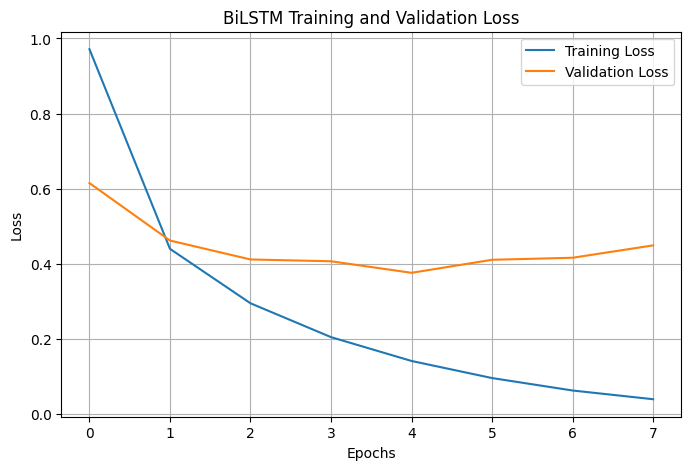

In [5]:
# -----------------------------------------
# 1. CREATE PYTORCH DATASET
# -----------------------------------------

class POSDataset(Dataset):

    def __init__(self, X, Y):
        self.X = X
        self.Y = Y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]


def collate_fn(batch):

    X, Y = zip(*batch)

    return prepare_batch(X, Y)


train_dataset = POSDataset(X_train, Y_train)
val_dataset = POSDataset(X_val, Y_val)
test_dataset = POSDataset(X_test, Y_test)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)


# -----------------------------------------
# 2. BUILD BiLSTM MODEL
# -----------------------------------------

class BiLSTM_POS(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_tags,
        pad_idx
    ):

        super(BiLSTM_POS, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_idx
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.fc = nn.Linear(
            hidden_dim * 2,
            num_tags
        )

    def forward(self, x):

        embedded = self.embedding(x)

        lstm_out, _ = self.lstm(embedded)

        output = self.fc(lstm_out)

        return output


# Hyperparameters
EMBEDDING_DIM = 100
HIDDEN_DIM = 128
NUM_TAGS = len(tag2idx)
LEARNING_RATE = 0.001
EPOCHS = 15


bilstm_model = BiLSTM_POS(
    vocab_size=len(word2idx),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_tags=NUM_TAGS,
    pad_idx=PAD_IDX
).to(device)

print(bilstm_model)


# -----------------------------------------
# 3. DISPLAY MODEL DIMENSIONS
# -----------------------------------------

sample_input = sample_X.to(device)

with torch.no_grad():

    embedding_output = bilstm_model.embedding(sample_input)

    lstm_output, _ = bilstm_model.lstm(embedding_output)

    final_output = bilstm_model.fc(lstm_output)

print("\nModel dimensions:")

print("Input:", sample_input.shape)
print("Embedding:", embedding_output.shape)
print("BiLSTM:", lstm_output.shape)
print("Linear output:", final_output.shape)


# -----------------------------------------
# 4. LOSS AND OPTIMIZER
# -----------------------------------------

criterion = nn.CrossEntropyLoss(
    ignore_index=-100
)

optimizer = torch.optim.Adam(
    bilstm_model.parameters(),
    lr=LEARNING_RATE
)


# -----------------------------------------
# 5. TRAINING FUNCTION
# -----------------------------------------

def train_bilstm_epoch(model, loader):

    model.train()

    total_loss = 0

    for X, Y, mask in loader:

        X = X.to(device)
        Y = Y.to(device)

        optimizer.zero_grad()

        outputs = model(X)

        loss = criterion(
            outputs.reshape(-1, NUM_TAGS),
            Y.reshape(-1)
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


# -----------------------------------------
# 6. VALIDATION FUNCTION
# -----------------------------------------

def validate_bilstm(model, loader):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for X, Y, mask in loader:

            X = X.to(device)
            Y = Y.to(device)

            outputs = model(X)

            loss = criterion(
                outputs.reshape(-1, NUM_TAGS),
                Y.reshape(-1)
            )

            total_loss += loss.item()

    return total_loss / len(loader)


# -----------------------------------------
# 7. TRAIN MODEL + EARLY STOPPING
# -----------------------------------------

train_losses = []
val_losses = []

best_val_loss = float("inf")
patience = 3
counter = 0

for epoch in range(EPOCHS):

    train_loss = train_bilstm_epoch(
        bilstm_model,
        train_loader
    )

    val_loss = validate_bilstm(
        bilstm_model,
        val_loader
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            bilstm_model.state_dict(),
            "best_bilstm.pt"
        )

        counter = 0

    else:

        counter += 1

    if counter >= patience:

        print("Early stopping!")
        break


# Load best model
bilstm_model.load_state_dict(
    torch.load("best_bilstm.pt", map_location=device)
)


# -----------------------------------------
# 8. PLOT TRAINING AND VALIDATION LOSS
# -----------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("BiLSTM Training and Validation Loss")

plt.legend()
plt.grid()
plt.show()

In [6]:
# -----------------------------------------
# EVALUATION FUNCTION
# -----------------------------------------

def evaluate_bilstm(model, loader):

    model.eval()

    actual = []
    predicted = []

    with torch.no_grad():

        for X, Y, mask in loader:

            X = X.to(device)
            Y = Y.to(device)

            outputs = model(X)

            preds = torch.argmax(outputs, dim=-1)

            valid = Y != -100

            actual.extend(
                Y[valid].cpu().numpy().tolist()
            )

            predicted.extend(
                preds[valid].cpu().numpy().tolist()
            )

    accuracy = accuracy_score(actual, predicted)

    precision, recall, f1, _ = precision_recall_fscore_support(
        actual,
        predicted,
        average="macro",
        zero_division=0
    )

    print("\nBiLSTM Test Results")

    print("Accuracy:", accuracy)
    print("Macro Precision:", precision)
    print("Macro Recall:", recall)
    print("Macro F1:", f1)

    return actual, predicted


bilstm_actual, bilstm_pred = evaluate_bilstm(
    bilstm_model,
    test_loader
)


BiLSTM Test Results
Accuracy: 0.889057145134295
Macro Precision: 0.8727808245003322
Macro Recall: 0.8109784034339553
Macro F1: 0.8311440449921762


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]


BERT Subword Mapping:
[CLS] -> Special Token
Al -> Al -> PROPN
- -> - -> PUNCT
Z -> Zaman -> PROPN
##aman -> Zaman -> PROPN
: -> : -> PUNCT
American -> American -> ADJ
forces -> forces -> NOUN
killed -> killed -> VERB
S -> Shaikh -> PROPN
##hai -> Shaikh -> PROPN
##kh -> Shaikh -> PROPN
Abdullah -> Abdullah -> PROPN
al -> al -> PROPN
- -> - -> PUNCT
An -> Ani -> PROPN
##i -> Ani -> PROPN
, -> , -> PUNCT
the -> the -> DET
preacher -> preacher -> NOUN
at -> at -> ADP
the -> the -> DET
mosque -> mosque -> NOUN
in -> in -> ADP
the -> the -> DET
town -> town -> NOUN
of -> of -> ADP
Q -> Qaim -> PROPN
##ai -> Qaim -> PROPN
##m -> Qaim -> PROPN
, -> , -> PUNCT
near -> near -> ADP
the -> the -> DET
Syrian -> Syrian -> ADJ
border -> border -> NOUN
. -> . -> PUNCT
[SEP] -> Special Token


model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly i

BertForTokenClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(28996, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, el

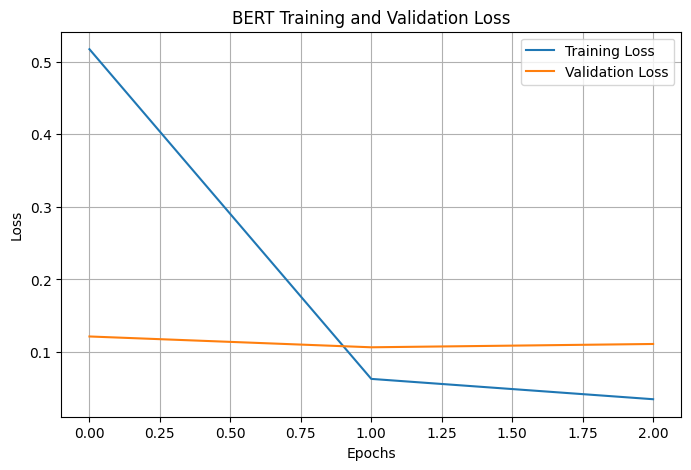

In [7]:
# -----------------------------------------
# 1. IMPORT BERT LIBRARIES
# -----------------------------------------

from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    get_linear_schedule_with_warmup
)

import time

MODEL_NAME = "bert-base-cased"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)


# -----------------------------------------
# 2. TOKENIZATION AND LABEL ALIGNMENT
# -----------------------------------------

class BERTPOSDataset(Dataset):

    def __init__(self, sentences):

        self.sentences = sentences

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, idx):
        return self.sentences[idx]


def bert_collate_fn(batch):

    words_batch = [item[0] for item in batch]
    tags_batch = [item[1] for item in batch]

    encoding = tokenizer(
        words_batch,
        is_split_into_words=True,
        padding=True,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    labels = []

    for i, tags in enumerate(tags_batch):

        word_ids = encoding.word_ids(batch_index=i)

        label_ids = []

        previous_word_id = None

        for word_id in word_ids:

            if word_id is None:

                label_ids.append(-100)

            elif word_id != previous_word_id:

                label_ids.append(
                    tag2idx[tags[word_id]]
                )

            else:

                label_ids.append(-100)

            previous_word_id = word_id

        labels.append(label_ids)

    encoding["labels"] = torch.tensor(
        labels,
        dtype=torch.long
    )

    return encoding


# -----------------------------------------
# 3. DISPLAY WORD TO SUBWORD MAPPING
# -----------------------------------------

example_words = train_sentences[0][0]
example_tags = train_sentences[0][1]

example_encoding = tokenizer(
    example_words,
    is_split_into_words=True
)

word_ids = example_encoding.word_ids()

tokens = tokenizer.convert_ids_to_tokens(
    example_encoding["input_ids"]
)

print("\nBERT Subword Mapping:")

for token, word_id in zip(tokens, word_ids):

    if word_id is None:
        print(token, "-> Special Token")

    else:
        print(
            token,
            "->",
            example_words[word_id],
            "->",
            example_tags[word_id]
        )


# -----------------------------------------
# 4. CREATE BERT DATALOADERS
# -----------------------------------------

bert_train_dataset = BERTPOSDataset(train_sentences)
bert_val_dataset = BERTPOSDataset(val_sentences)
bert_test_dataset = BERTPOSDataset(test_sentences)

bert_train_loader = DataLoader(
    bert_train_dataset,
    batch_size=16,
    shuffle=True,
    collate_fn=bert_collate_fn
)

bert_val_loader = DataLoader(
    bert_val_dataset,
    batch_size=16,
    shuffle=False,
    collate_fn=bert_collate_fn
)

bert_test_loader = DataLoader(
    bert_test_dataset,
    batch_size=16,
    shuffle=False,
    collate_fn=bert_collate_fn
)


# -----------------------------------------
# 5. LOAD PRETRAINED BERT MODEL
# -----------------------------------------

bert_model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(tag2idx),
    id2label=idx2tag,
    label2id=tag2idx
).to(device)

print(bert_model)


# -----------------------------------------
# 6. OPTIMIZER AND SCHEDULER
# -----------------------------------------

BERT_EPOCHS = 3
BERT_LR = 2e-5

bert_optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=BERT_LR
)

total_steps = len(bert_train_loader) * BERT_EPOCHS

scheduler = get_linear_schedule_with_warmup(
    bert_optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)


# -----------------------------------------
# 7. BERT TRAINING FUNCTION
# -----------------------------------------

def train_bert_epoch():

    bert_model.train()

    total_loss = 0

    for batch in bert_train_loader:

        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }

        bert_optimizer.zero_grad()

        outputs = bert_model(**batch)

        loss = outputs.loss

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            bert_model.parameters(),
            1.0
        )

        bert_optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    return total_loss / len(bert_train_loader)


# -----------------------------------------
# 8. BERT VALIDATION FUNCTION
# -----------------------------------------

def validate_bert():

    bert_model.eval()

    total_loss = 0

    with torch.no_grad():

        for batch in bert_val_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = bert_model(**batch)

            total_loss += outputs.loss.item()

    return total_loss / len(bert_val_loader)


# -----------------------------------------
# 9. FINE-TUNE BERT
# -----------------------------------------

bert_train_losses = []
bert_val_losses = []

best_bert_loss = float("inf")
patience = 2
counter = 0

start_time = time.time()

for epoch in range(BERT_EPOCHS):

    train_loss = train_bert_epoch()

    val_loss = validate_bert()

    bert_train_losses.append(train_loss)
    bert_val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{BERT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    if val_loss < best_bert_loss:

        best_bert_loss = val_loss

        torch.save(
            bert_model.state_dict(),
            "best_bert_pos.pt"
        )

        counter = 0

    else:

        counter += 1

    if counter >= patience:

        print("Early stopping!")
        break


bert_training_time = time.time() - start_time

bert_model.load_state_dict(
    torch.load("best_bert_pos.pt", map_location=device)
)

print(
    "BERT Training Time:",
    round(bert_training_time, 2),
    "seconds"
)


# -----------------------------------------
# 10. PLOT BERT TRAINING CURVES
# -----------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    bert_train_losses,
    label="Training Loss"
)

plt.plot(
    bert_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.title("BERT Training and Validation Loss")

plt.legend()
plt.grid()
plt.show()

In [8]:
# -----------------------------------------
# EVALUATE BERT ON TEST DATA
# -----------------------------------------

def evaluate_bert():

    bert_model.eval()

    actual = []
    predicted = []

    with torch.no_grad():

        for batch in bert_test_loader:

            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            outputs = bert_model(**batch)

            predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            labels = batch["labels"]

            valid = labels != -100

            actual.extend(
                labels[valid].cpu().numpy().tolist()
            )

            predicted.extend(
                predictions[valid].cpu().numpy().tolist()
            )

    accuracy = accuracy_score(actual, predicted)

    precision, recall, f1, _ = precision_recall_fscore_support(
        actual,
        predicted,
        average="macro",
        zero_division=0
    )

    print("\nBERT Test Results")

    print("Accuracy:", accuracy)
    print("Macro Precision:", precision)
    print("Macro Recall:", recall)
    print("Macro F1:", f1)

    return actual, predicted


bert_actual, bert_pred = evaluate_bert()


BERT Test Results
Accuracy: 0.9721048856300311
Macro Precision: 0.9569503550126299
Macro Recall: 0.9215392969532509
Macro F1: 0.9318630814800943


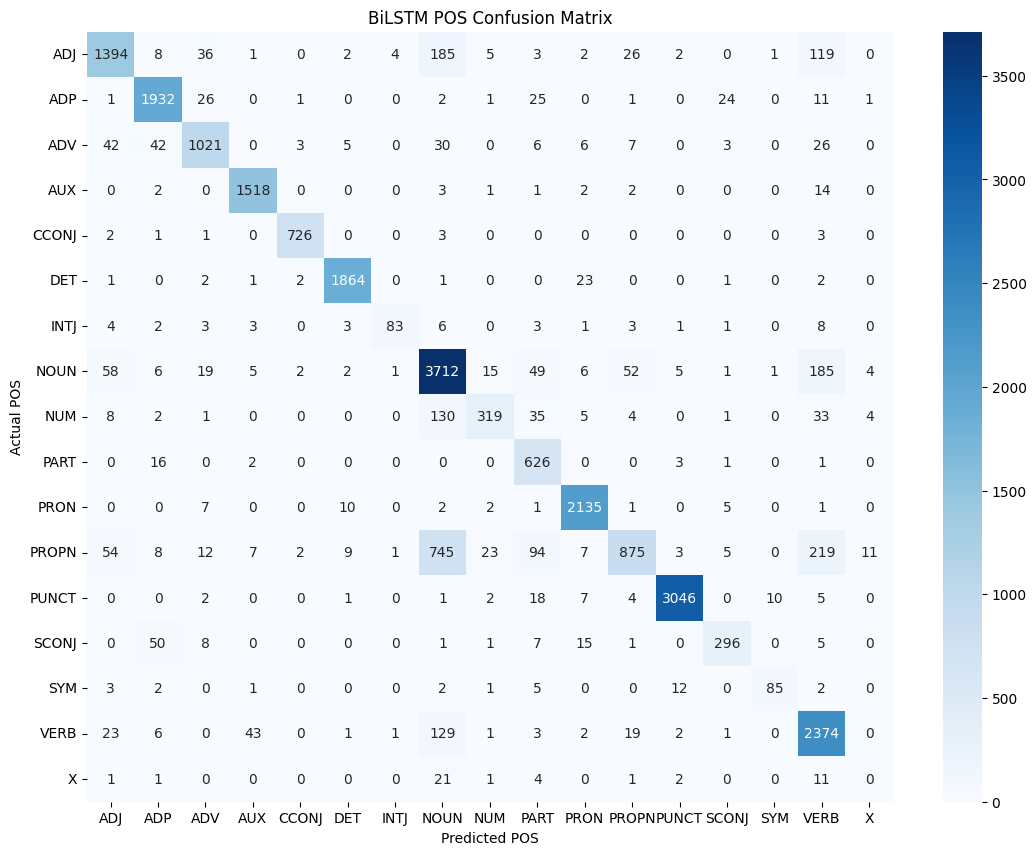

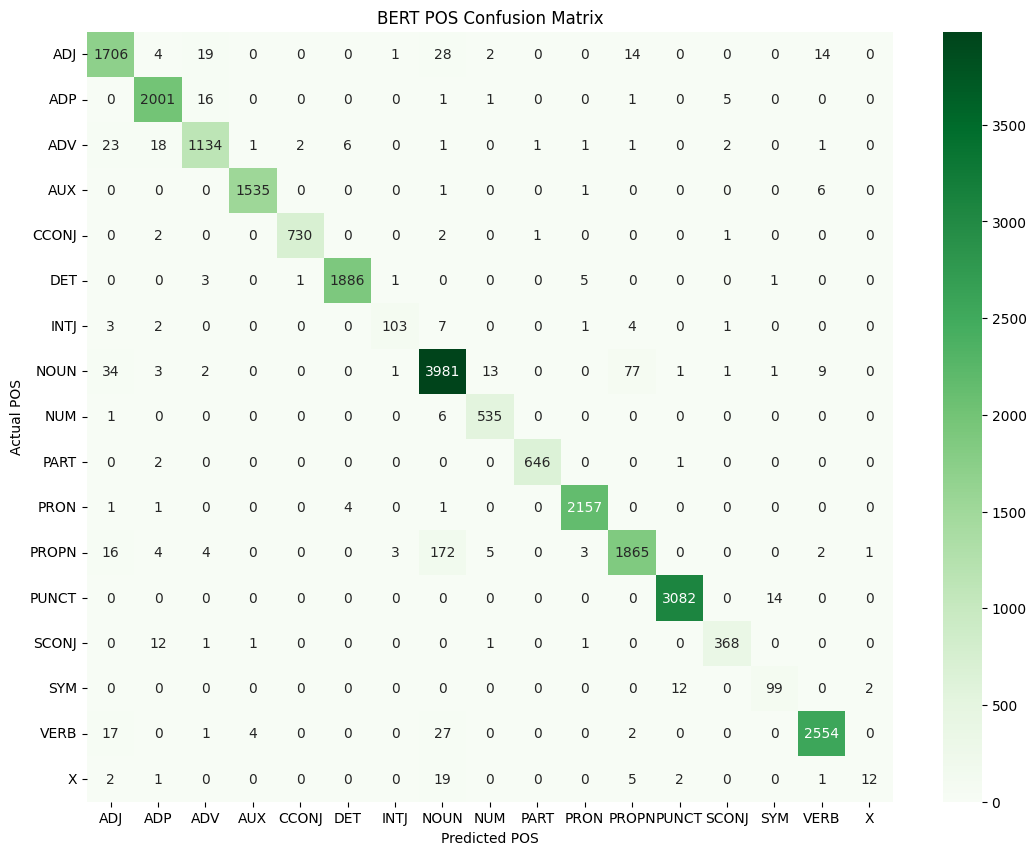


BiLSTM Incorrect Predictions:
                                                                                                        Sentence Target Word Actual Tag Predicted Tag
                                                                          What if Google Morphed Into GoogleOS ?        Into        ADP             X
                                                                          What if Google Morphed Into GoogleOS ?    GoogleOS      PROPN          NOUN
What if Google expanded on its search - engine ( and now e-mail ) wares into a full - fledged operating system ?       wares       NOUN          VERB
What if Google expanded on its search - engine ( and now e-mail ) wares into a full - fledged operating system ?        full        ADV           ADJ
What if Google expanded on its search - engine ( and now e-mail ) wares into a full - fledged operating system ?     fledged        ADJ          NOUN

BERT Incorrect Predictions:
                                        

In [9]:
# -----------------------------------------
# 1. GET BiLSTM PREDICTIONS BY SENTENCE
# -----------------------------------------

def get_bilstm_predictions(model, X, Y):

    model.eval()

    results = []

    with torch.no_grad():

        for x, y in zip(X, Y):

            x_batch = x.unsqueeze(0).to(device)

            outputs = model(x_batch)

            preds = torch.argmax(
                outputs,
                dim=-1
            )[0].cpu().tolist()

            results.append(preds[:len(y)])

    return results


bilstm_sentence_preds = get_bilstm_predictions(
    bilstm_model,
    X_test,
    Y_test
)


# -----------------------------------------
# 2. GET BERT PREDICTIONS BY SENTENCE
# -----------------------------------------

def get_bert_predictions(sentences):

    bert_model.eval()

    all_predictions = []

    with torch.no_grad():

        for words, tags in sentences:

            encoding = tokenizer(
                words,
                is_split_into_words=True,
                truncation=True,
                max_length=256,
                return_tensors="pt"
            )

            encoding = {
                key: value.to(device)
                for key, value in encoding.items()
            }

            outputs = bert_model(**encoding)

            preds = torch.argmax(
                outputs.logits,
                dim=-1
            )[0].cpu().tolist()

            word_ids = tokenizer(
                words,
                is_split_into_words=True,
                truncation=True,
                max_length=256
            ).word_ids()

            sentence_predictions = {}

            for pred, word_id in zip(preds, word_ids):

                if word_id is not None and word_id not in sentence_predictions:

                    sentence_predictions[word_id] = pred

            all_predictions.append(sentence_predictions)

    return all_predictions


bert_sentence_preds = get_bert_predictions(test_sentences)


# -----------------------------------------
# 3. PREPARE COMPARABLE TEST PREDICTIONS
# -----------------------------------------

bilstm_true = []
bilstm_predictions = []

bert_true = []
bert_predictions = []

for i, (words, tags) in enumerate(test_sentences):

    for j, (word, tag) in enumerate(zip(words, tags)):

        true_id = tag2idx[tag]

        # BiLSTM prediction
        pred_id = bilstm_sentence_preds[i][j]

        bilstm_true.append(true_id)
        bilstm_predictions.append(pred_id)

        # BERT prediction
        if j in bert_sentence_preds[i]:

            bert_true.append(true_id)
            bert_predictions.append(
                bert_sentence_preds[i][j]
            )


# -----------------------------------------
# 4. CONFUSION MATRIX - BiLSTM
# -----------------------------------------

plt.figure(figsize=(13, 10))

cm_bilstm = confusion_matrix(
    bilstm_true,
    bilstm_predictions,
    labels=list(range(NUM_TAGS))
)

sns.heatmap(
    cm_bilstm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=all_tags,
    yticklabels=all_tags
)

plt.xlabel("Predicted POS")
plt.ylabel("Actual POS")

plt.title("BiLSTM POS Confusion Matrix")

plt.show()


# -----------------------------------------
# 5. CONFUSION MATRIX - BERT
# -----------------------------------------

plt.figure(figsize=(13, 10))

cm_bert = confusion_matrix(
    bert_true,
    bert_predictions,
    labels=list(range(NUM_TAGS))
)

sns.heatmap(
    cm_bert,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=all_tags,
    yticklabels=all_tags
)

plt.xlabel("Predicted POS")
plt.ylabel("Actual POS")

plt.title("BERT POS Confusion Matrix")

plt.show()


# -----------------------------------------
# 6. DISPLAY INCORRECT BiLSTM PREDICTIONS
# -----------------------------------------

bilstm_errors = []

for i, (words, tags) in enumerate(test_sentences):

    preds = bilstm_sentence_preds[i]

    for j, (word, actual_tag) in enumerate(zip(words, tags)):

        predicted_tag = idx2tag[preds[j]]

        if actual_tag != predicted_tag:

            bilstm_errors.append({
                "Sentence": " ".join(words),
                "Target Word": word,
                "Actual Tag": actual_tag,
                "Predicted Tag": predicted_tag
            })

print("\nBiLSTM Incorrect Predictions:")

bilstm_error_df = pd.DataFrame(bilstm_errors)

print(
    bilstm_error_df.head(5).to_string(index=False)
)


# -----------------------------------------
# 7. DISPLAY INCORRECT BERT PREDICTIONS
# -----------------------------------------

bert_errors = []

for i, (words, tags) in enumerate(test_sentences):

    preds = bert_sentence_preds[i]

    for j, (word, actual_tag) in enumerate(zip(words, tags)):

        if j not in preds:
            continue

        predicted_tag = idx2tag[preds[j]]

        if actual_tag != predicted_tag:

            bert_errors.append({
                "Sentence": " ".join(words),
                "Target Word": word,
                "Actual Tag": actual_tag,
                "Predicted Tag": predicted_tag
            })

print("\nBERT Incorrect Predictions:")

bert_error_df = pd.DataFrame(bert_errors)

print(
    bert_error_df.head(5).to_string(index=False)
)


# -----------------------------------------
# 8. AMBIGUOUS WORD ANALYSIS: BOOK
# -----------------------------------------

print("\nAmbiguous Word Analysis: BOOK")

for i, (words, tags) in enumerate(test_sentences):

    for j, word in enumerate(words):

        if word.lower() == "book":

            bilstm_tag = idx2tag[
                bilstm_sentence_preds[i][j]
            ]

            bert_tag = (
                idx2tag[bert_sentence_preds[i][j]]
                if j in bert_sentence_preds[i]
                else "NOT AVAILABLE"
            )

            print("\nSentence:", " ".join(words))
            print("Word:", word)
            print("Actual:", tags[j])
            print("BiLSTM:", bilstm_tag)
            print("BERT:", bert_tag)


# -----------------------------------------
# 9. RARE AND UNKNOWN WORD ANALYSIS
# -----------------------------------------

print("\nRare Word Analysis")

rare_words = {
    word
    for word, count in word_counter.items()
    if count <= 2
}

rare_errors = []

for i, (words, tags) in enumerate(test_sentences):

    for j, word in enumerate(words):

        if word in rare_words:

            pred = idx2tag[
                bilstm_sentence_preds[i][j]
            ]

            if pred != tags[j]:

                rare_errors.append({
                    "Word": word,
                    "Actual": tags[j],
                    "Predicted": pred,
                    "Sentence": " ".join(words)
                })

print("Rare words in training vocabulary:", len(rare_words))

print("\nRare word errors:")

print(
    pd.DataFrame(rare_errors).head(10).to_string(index=False)
)


# Check unknown words
unknown_count = sum(
    word not in word2idx
    for words, tags in test_sentences
    for word in words
)

print("\nUnknown test tokens:", unknown_count)


# -----------------------------------------
# 10. LONG SENTENCE ERROR ANALYSIS
# -----------------------------------------

print("\nLong Sentence Analysis")

for i, (words, tags) in enumerate(test_sentences):

    if len(words) >= 40:

        errors = sum(
            idx2tag[bilstm_sentence_preds[i][j]] != tags[j]
            for j in range(len(words))
        )

        print(
            "Sentence length:", len(words),
            "| Errors:", errors,
            "| Sentence:", " ".join(words)[:200]
        )

        break


# -----------------------------------------
# 11. FINAL COMPARISON TABLE
# -----------------------------------------

def calculate_metrics(actual, predicted):

    accuracy = accuracy_score(actual, predicted)

    precision, recall, f1, _ = precision_recall_fscore_support(
        actual,
        predicted,
        average="macro",
        zero_division=0
    )

    return accuracy, precision, recall, f1


bilstm_metrics = calculate_metrics(
    bilstm_true,
    bilstm_predictions
)

bert_metrics = calculate_metrics(
    bert_true,
    bert_predictions
)

comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],

    "BiLSTM": bilstm_metrics,

    "BERT": bert_metrics

})

print("\nFINAL MODEL COMPARISON")

print(comparison.to_string(index=False))